STEP 1: Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

STEP 2: Load dataset

In [5]:
df=pd.read_csv("india_flight_delay_model_input.csv")

STEP 3:Data Understanding

In [6]:
df.head()

,Flight_Date,Airline,Flight_Number,Origin_Airport,Destination_Airport,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,...,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target
0,2025-12-04,IndiGo,IN8723,BOM,DEL,13,57,3,12,0,...,46.1,4.3,9.8,5.2,0.0,63.5,0,23.9,43,1
1,2024-01-15,IndiGo,IN558,CCU,HYD,19,14,0,1,0,...,70.5,8.9,11.7,0.4,39.8,95.3,1,31.5,49,1
2,2023-11-06,Vistara,VI4949,HYD,DEL,8,50,0,11,0,...,53.7,7.8,9.6,4.3,16.6,100.0,1,41.5,73,1
3,2025-08-08,SpiceJet,SP3196,BLR,DIB,11,56,4,8,0,...,42.0,1.5,12.6,4.6,23.6,51.1,1,28.2,40,1
4,2023-09-09,IndiGo,IN8458,BLR,JGA,22,59,5,9,1,...,58.5,1.3,11.3,3.5,36.2,67.0,0,27.9,0,0


In [7]:
df.tail()

,Flight_Date,Airline,Flight_Number,Origin_Airport,Destination_Airport,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,...,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target
149995,2024-07-08,IndiGo,IN5273,BOM,AMD,5,49,0,7,0,...,55.3,14.0,11.1,0.8,25.7,78.2,0,46.1,51,1
149996,2025-03-21,Air India Express,AI8983,COK,DEL,11,32,4,3,0,...,80.3,2.3,11.2,0.0,29.1,73.7,8,40.4,46,1
149997,2023-04-11,IndiGo,IN2669,DEL,CCU,9,6,1,4,0,...,36.7,2.2,9.8,0.1,32.8,84.8,7,40.5,50,1
149998,2025-05-04,Air India,AI8266,IXR,COK,6,42,6,5,1,...,53.8,3.5,8.8,3.0,16.6,35.5,0,21.0,0,0
149999,2024-06-17,Fly91,FL5153,MAA,DEL,9,20,0,6,0,...,53.5,12.5,9.8,3.0,25.5,91.8,6,42.8,53,1


In [8]:
df.shape

(150000, 23)

In [9]:
df.size

3450000

In [10]:
df.columns

Index(['Flight_Date', 'Airline', 'Flight_Number', 'Origin_Airport',
       'Destination_Airport', 'Scheduled_Departure_Hour',
       'Scheduled_Departure_Minute', 'Day_of_Week', 'Month', 'Is_Weekend',
       'Peak_Hour', 'Weather', 'Temperature_C', 'Humidity_pct',
       'Wind_Speed_kmh', 'Visibility_km', 'Rainfall_mm', 'Cloud_Cover_pct',
       'Origin_Congestion_Index', 'Previous_Flight_Delay_Minutes',
       'Turnaround_Risk_Index', 'Departure_Delay', 'Delay_Target'],
      dtype='object')

In [11]:
df.index

RangeIndex(start=0, stop=150000, step=1)

In [12]:
df.dtypes

,0
Flight_Date,object
Airline,object
Flight_Number,object
Origin_Airport,object
Destination_Airport,object
Scheduled_Departure_Hour,int64
Scheduled_Departure_Minute,int64
Day_of_Week,int64
Month,int64
Is_Weekend,int64


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Flight_Date                    150000 non-null  object 
 1   Airline                        150000 non-null  object 
 2   Flight_Number                  150000 non-null  object 
 3   Origin_Airport                 150000 non-null  object 
 4   Destination_Airport            150000 non-null  object 
 5   Scheduled_Departure_Hour       150000 non-null  int64  
 6   Scheduled_Departure_Minute     150000 non-null  int64  
 7   Day_of_Week                    150000 non-null  int64  
 8   Month                          150000 non-null  int64  
 9   Is_Weekend                     150000 non-null  int64  
 10  Peak_Hour                      150000 non-null  int64  
 11  Weather                        150000 non-null  object 
 12  Temperature_C                 

In [14]:
df.describe()

,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,Peak_Hour,Temperature_C,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.00000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,14.001260,29.533773,2.997107,6.512973,0.286820,0.47528,27.028051,56.332991,5.993765,10.891581,1.666205,25.013692,72.406212,6.170807,35.715187,42.664340,0.866167
std,5.480291,17.322034,2.003977,3.445167,0.452278,0.49939,5.489234,10.161597,4.223185,1.271557,2.409718,13.020552,19.277706,6.483483,8.719541,19.016712,0.340474
min,5.000000,0.000000,0.000000,1.000000,0.000000,0.00000,10.000000,20.000000,0.000000,5.100000,0.000000,0.000000,0.000000,0.000000,0.400000,0.000000,0.000000
25%,9.000000,15.000000,1.000000,4.000000,0.000000,0.00000,22.900000,49.500000,2.900000,10.000000,0.000000,15.800000,60.900000,1.000000,29.900000,39.000000,1.000000
50%,14.000000,30.000000,3.000000,7.000000,0.000000,0.00000,27.000000,56.300000,5.000000,10.900000,0.600000,24.800000,72.700000,4.000000,35.700000,47.000000,1.000000
75%,19.000000,45.000000,5.000000,10.000000,1.000000,1.00000,31.100000,63.200000,8.100000,11.700000,2.500000,33.800000,88.800000,9.000000,41.500000,54.000000,1.000000
max,23.000000,59.000000,6.000000,12.000000,1.000000,1.00000,45.000000,100.000000,35.000000,15.000000,30.400000,90.100000,100.000000,71.000000,88.200000,119.000000,1.000000


STEP 4:Data Cleaning

In [15]:
df.isnull().sum()

,0
Flight_Date,0
Airline,0
Flight_Number,0
Origin_Airport,0
Destination_Airport,0
Scheduled_Departure_Hour,0
Scheduled_Departure_Minute,0
Day_of_Week,0
Month,0
Is_Weekend,0


In [16]:
df.isnull().sum().sum()

np.int64(0)

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df['Flight_Date'] = pd.to_datetime(df['Flight_Date'])

In [19]:
df['Year'] = df['Flight_Date'].dt.year
df['Day'] = df['Flight_Date'].dt.day

In [20]:
df.drop(['Flight_Date', 'Flight_Number'], axis=1, inplace=True)

In [21]:
print(df.head())
print(df.shape)

    Airline Origin_Airport Destination_Airport  Scheduled_Departure_Hour  \
0    IndiGo            BOM                 DEL                        13   
1    IndiGo            CCU                 HYD                        19   
2   Vistara            HYD                 DEL                         8   
3  SpiceJet            BLR                 DIB                        11   
4    IndiGo            BLR                 JGA                        22   

   Scheduled_Departure_Minute  Day_of_Week  Month  Is_Weekend  Peak_Hour  \
0                          57            3     12           0          0   
1                          14            0      1           0          1   
2                          50            0     11           0          1   
3                          56            4      8           0          0   
4                          59            5      9           1          0   

               Weather  ...  Visibility_km  Rainfall_mm  Cloud_Cover_pct  \
0         

STEO 5: EDA

In [22]:
df.shape

(150000, 23)

In [23]:
df.head()

,Airline,Origin_Airport,Destination_Airport,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,Peak_Hour,Weather,...,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target,Year,Day
0,IndiGo,BOM,DEL,13,57,3,12,0,0,Rain,...,9.8,5.2,0.0,63.5,0,23.9,43,1,2025,4
1,IndiGo,CCU,HYD,19,14,0,1,0,1,Clear/Partly Cloudy,...,11.7,0.4,39.8,95.3,1,31.5,49,1,2024,15
2,Vistara,HYD,DEL,8,50,0,11,0,1,Rain,...,9.6,4.3,16.6,100.0,1,41.5,73,1,2023,6
3,SpiceJet,BLR,DIB,11,56,4,8,0,0,Rain,...,12.6,4.6,23.6,51.1,1,28.2,40,1,2025,8
4,IndiGo,BLR,JGA,22,59,5,9,1,0,Rain,...,11.3,3.5,36.2,67.0,0,27.9,0,0,2023,9


In [24]:
df.describe()

,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,Peak_Hour,Temperature_C,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target,Year,Day
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.00000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,14.001260,29.533773,2.997107,6.512973,0.286820,0.47528,27.028051,56.332991,5.993765,10.891581,1.666205,25.013692,72.406212,6.170807,35.715187,42.664340,0.866167,2023.996900,15.744393
std,5.480291,17.322034,2.003977,3.445167,0.452278,0.49939,5.489234,10.161597,4.223185,1.271557,2.409718,13.020552,19.277706,6.483483,8.719541,19.016712,0.340474,0.814871,8.783515
min,5.000000,0.000000,0.000000,1.000000,0.000000,0.00000,10.000000,20.000000,0.000000,5.100000,0.000000,0.000000,0.000000,0.000000,0.400000,0.000000,0.000000,2023.000000,1.000000
25%,9.000000,15.000000,1.000000,4.000000,0.000000,0.00000,22.900000,49.500000,2.900000,10.000000,0.000000,15.800000,60.900000,1.000000,29.900000,39.000000,1.000000,2023.000000,8.000000
50%,14.000000,30.000000,3.000000,7.000000,0.000000,0.00000,27.000000,56.300000,5.000000,10.900000,0.600000,24.800000,72.700000,4.000000,35.700000,47.000000,1.000000,2024.000000,16.000000
75%,19.000000,45.000000,5.000000,10.000000,1.000000,1.00000,31.100000,63.200000,8.100000,11.700000,2.500000,33.800000,88.800000,9.000000,41.500000,54.000000,1.000000,2025.000000,23.000000
max,23.000000,59.000000,6.000000,12.000000,1.000000,1.00000,45.000000,100.000000,35.000000,15.000000,30.400000,90.100000,100.000000,71.000000,88.200000,119.000000,1.000000,2025.000000,31.000000


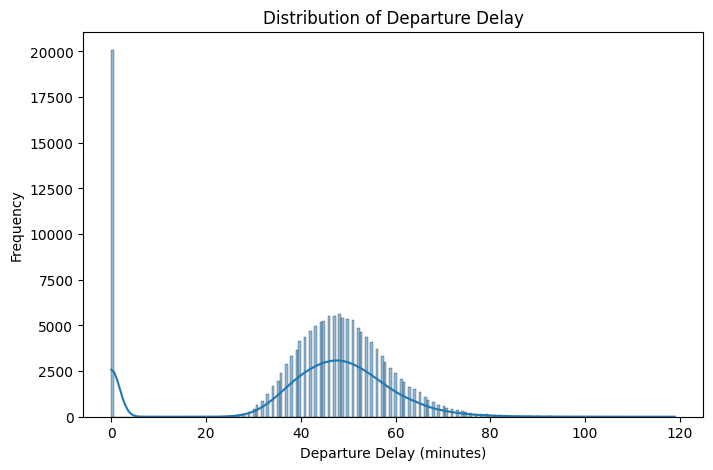

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['Departure_Delay'], kde=True)
plt.title('Distribution of Departure Delay')
plt.xlabel('Departure Delay (minutes)')
plt.ylabel('Frequency')
plt.show()

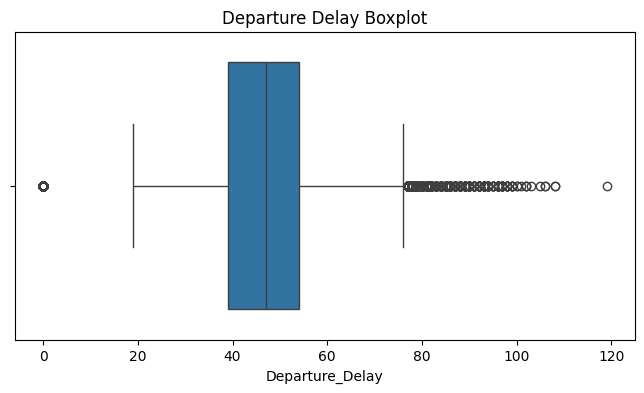

In [26]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Departure_Delay'])
plt.title('Departure Delay Boxplot')
plt.show()

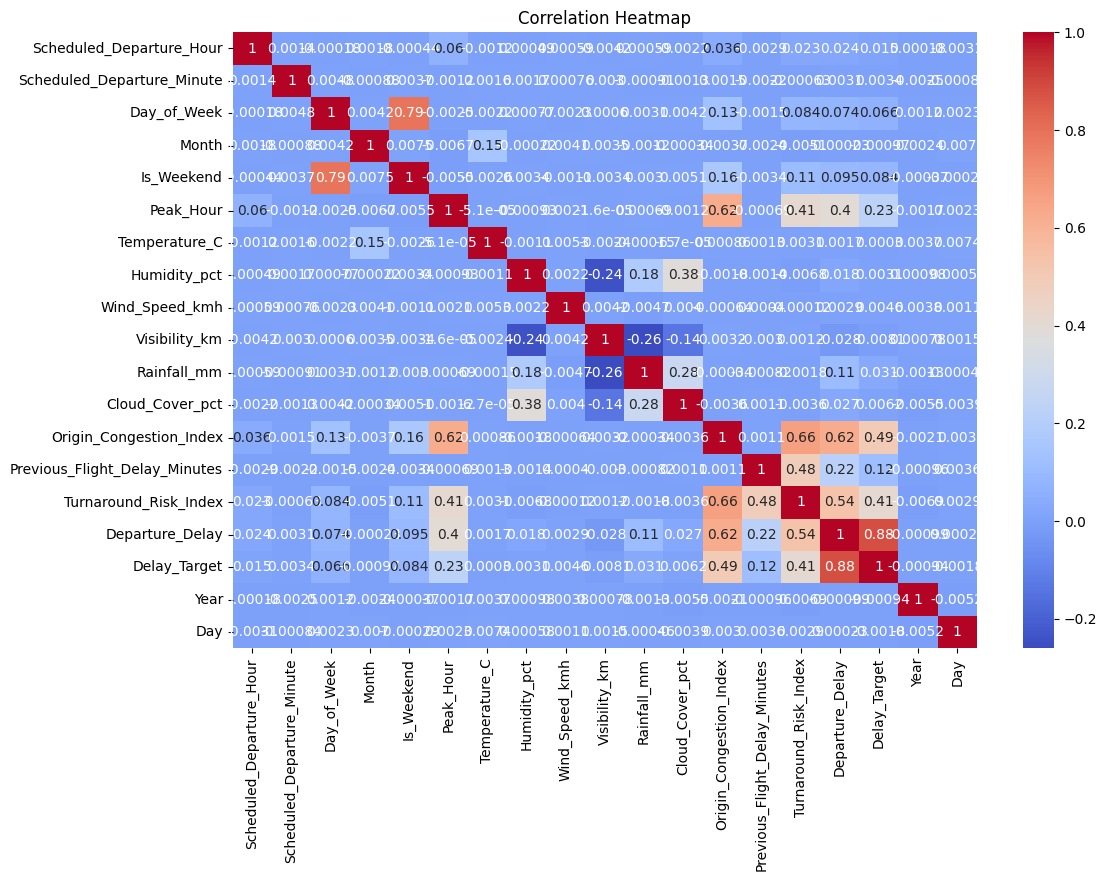

In [27]:
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

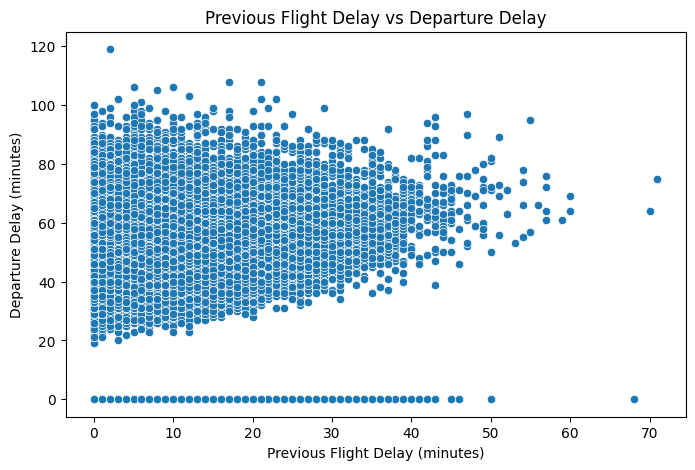

In [28]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x=df['Previous_Flight_Delay_Minutes'],
    y=df['Departure_Delay']
)

plt.title('Previous Flight Delay vs Departure Delay')
plt.xlabel('Previous Flight Delay (minutes)')
plt.ylabel('Departure Delay (minutes)')
plt.show()

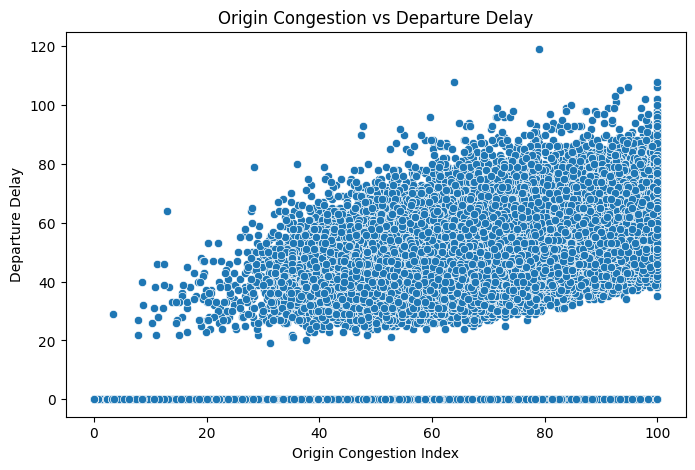

In [29]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x=df['Origin_Congestion_Index'],
    y=df['Departure_Delay']
)

plt.title('Origin Congestion vs Departure Delay')
plt.xlabel('Origin Congestion Index')
plt.ylabel('Departure Delay')
plt.show()

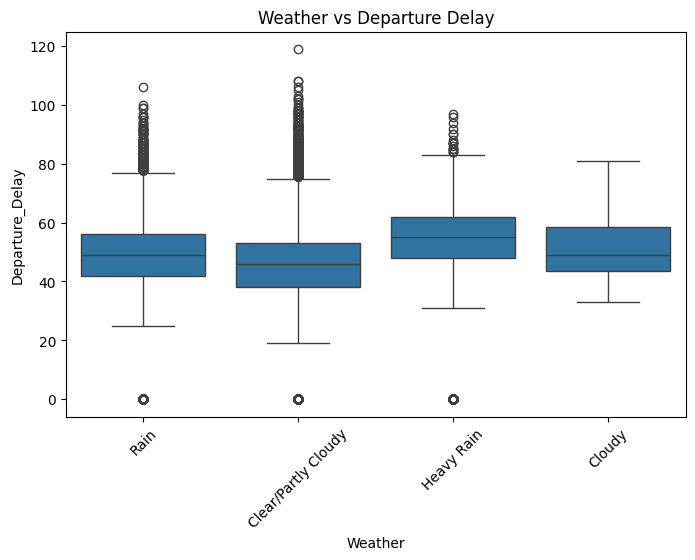

In [30]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x='Weather',
    y='Departure_Delay',
    data=df
)

plt.title('Weather vs Departure Delay')
plt.xticks(rotation=45)
plt.show()

STEP 6: Select X and Y

In [31]:
X = df.drop(['Delay_Target', 'Departure_Delay'], axis=1)

In [32]:
y = df['Delay_Target']

In [33]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150000, 21)
y shape: (150000,)


STEP 7: Categorical Data Encoding

In [34]:
X = pd.get_dummies(
    X,
    columns=[
        'Airline',
        'Origin_Airport',
        'Destination_Airport',
        'Weather'
    ],
    drop_first=True
)

In [35]:
print(X.dtypes[X.dtypes == 'object'])

Series([], dtype: object)


In [36]:
X = X.astype(float)

In [37]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150000, 198)
y shape: (150000,)


STEP 8: Train-Test Split

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (120000, 198)
X_test shape: (30000, 198)
y_train shape: (120000,)
y_test shape: (30000,)


STEP 9: Linear Regression Model

In [39]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed")

Model training completed


STEP 10:Prediction

In [40]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[0.87126414 0.91814987 0.85369978 0.83297226 0.83789366 0.91058681
 0.95122859 0.87502588 1.09497826 0.66889417]


In [41]:
y_pred = model.predict(X_test)

print(y_pred[9])

0.6688941660947036


STEP 11:Model Evaluation

In [42]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 0.200067673082728


In [43]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 0.08324215031103564


In [44]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 0.28851715774115694


In [45]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.28054813909077825


STEP 12: Actual vs Predicted

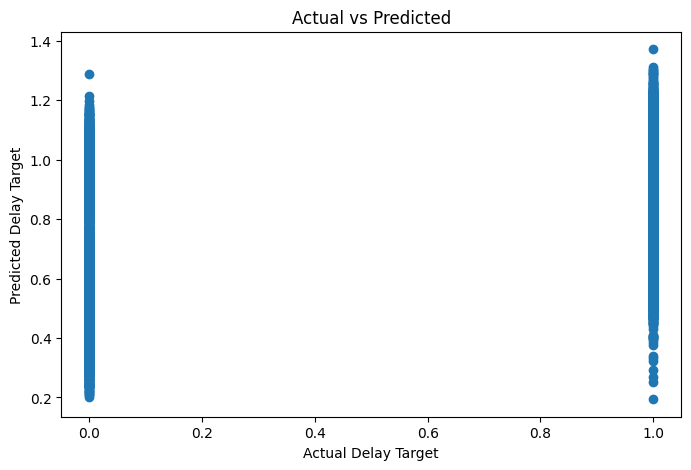

In [46]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Delay Target')
plt.ylabel('Predicted Delay Target')
plt.title('Actual vs Predicted')

plt.show()

STEP 13: Deployment

In [48]:
import pickle

with open('flight_delay_model.pkl','wb') as f:
    pickle.dump(model,f)

with open('flight_delay_model.pkl','rb') as f:
    mp=pickle.load(f)

print("Model loaded successfully")

Model loaded successfully


In [49]:
# Original model prediction
original_prediction = model.predict(X_test.iloc[[0]])

# Pickle model prediction
pickle_prediction = mp.predict(X_test.iloc[[0]])

print("Original Model Prediction:", original_prediction[0])
print("Pickle Model Prediction:", pickle_prediction[0])

Original Model Prediction: 0.8712641439479869
Pickle Model Prediction: 0.8712641439479869
